In [ ]:
import sys, site, importlib

!pip install --user -q nucleus-cdk==0.6.0rc1
!pip install --user -q pyarrow

user_site = site.getusersitepackages()
if user_site not in sys.path:
    sys.path.insert(0, user_site)
importlib.invalidate_caches()

import importlib.metadata as md
assert md.version("nucleus-cdk") == "0.6.0rc1", f"got {md.version('nucleus-cdk')}"

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.INFO)

# Import the cdk platereader module
from cdk.instruments import platereader as pr

INFO:cdk.logging:Logging initialized


In [ ]:
import sys
sys.path

['/content',
 '/env/python',
 '/usr/lib/python313.zip',
 '/usr/lib/python3.13',
 '/usr/lib/python3.13/lib-dynload',
 '',
 '/usr/local/lib/python3.13/dist-packages',
 '/usr/lib/python3/dist-packages',
 '/usr/local/lib/python3.13/dist-packages/IPython/extensions',
 '/root/.ipython']

In [ ]:
from cdk.analysis.cell import microscopy as m

## Load data

Will put a proper read parquet in the actual microscopy CDK code. Once that's done there's a load function that will also take a platemap (like the the platereader).

In [ ]:
data = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/2026-07-30-Day4_v3_%2B4.5hr_2026-07-30_19-05-12.985590.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

# data = data.merge(platemap, on="Well")
# data = data.sort_values(by=["Experiment", "Name", "Timepoint"])

In [ ]:
data.head()

,Label,Area (um^2),Diameter (Equivalent) (um),Diameter (Feret) (um),Length Major (um),Length Minor (um),Perimeter (um),Intensity Mean (GFP),Intensity Mean (Alexa Fluor 647),Intensity Max (GFP),...,Centroid.1,Volume (um^3),Circularity,Intensity Sum (GFP),Intensity Norm (GFP),Intensity Sum (Alexa Fluor 647),Intensity Norm (Alexa Fluor 647),Timepoint,Dataset,Well
0,1,153.803043,13.993860,16.653330,15.776393,12.658431,47.993589,619.854362,434.016583,677.0,...,20.747557,1434.865496,0.839090,859738,0.431995,601981,0.302479,0,/data/microscopy/2026-07-30-Day4_v3_+4.5hr_202...,O10
1,2,8.871120,3.360813,3.723053,3.426432,3.292147,10.232398,654.900000,458.900000,712.0,...,636.267263,19.876114,1.064715,52392,32.949096,36712,23.088014,0,/data/microscopy/2026-07-30-Day4_v3_+4.5hr_202...,O10
2,3,6.764229,2.934703,3.159115,2.987155,2.884180,8.705331,650.655738,459.918033,698.0,...,217.705574,13.234004,1.121651,39690,49.165449,28055,34.752751,0,/data/microscopy/2026-07-30-Day4_v3_+4.5hr_202...,O10
3,4,11.532456,3.831916,4.329000,4.145439,3.548935,11.840264,644.394231,468.442308,689.0,...,733.390875,29.460934,1.033734,67017,21.872838,48718,15.900457,0,/data/microscopy/2026-07-30-Day4_v3_+4.5hr_202...,O10
4,5,7.318674,3.052610,3.279670,3.093502,2.997577,9.095465,658.439394,546.439394,705.0,...,316.037182,14.894036,1.111712,43457,44.208258,36065,36.688470,0,/data/microscopy/2026-07-30-Day4_v3_+4.5hr_202...,O10


## Summary Plots

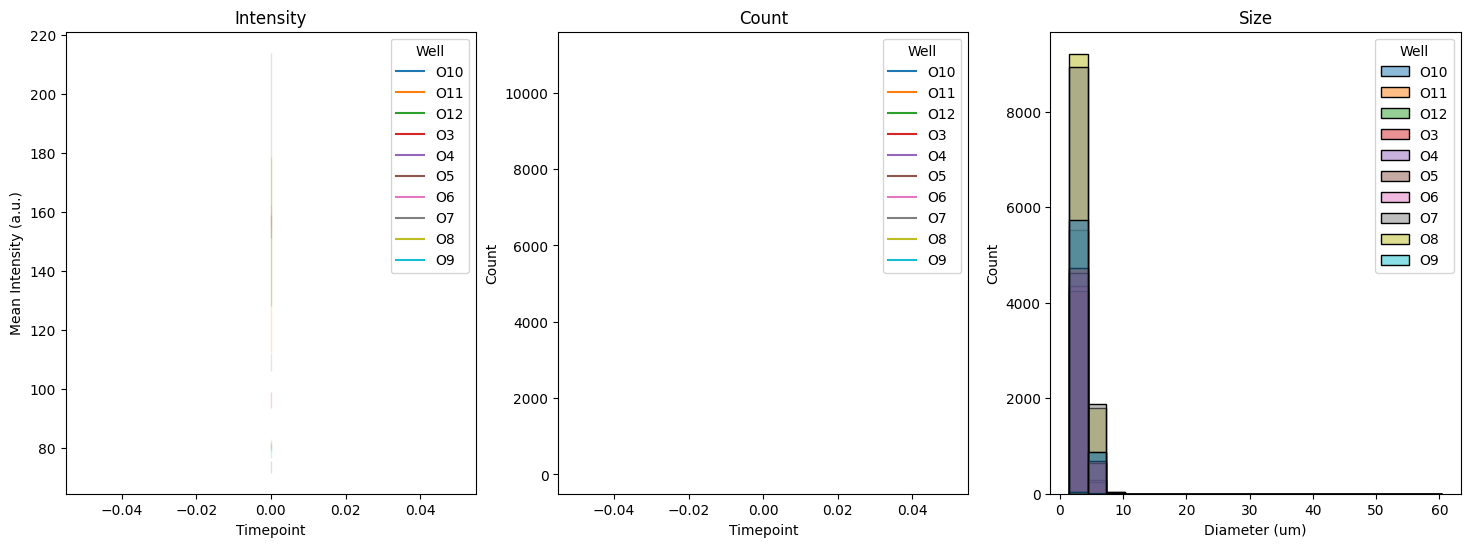

In [ ]:
m.plot_summary(data)

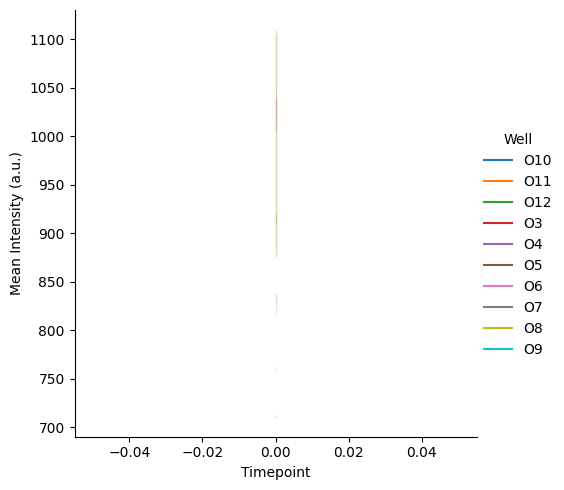

In [ ]:
m.plot_intensity(data)

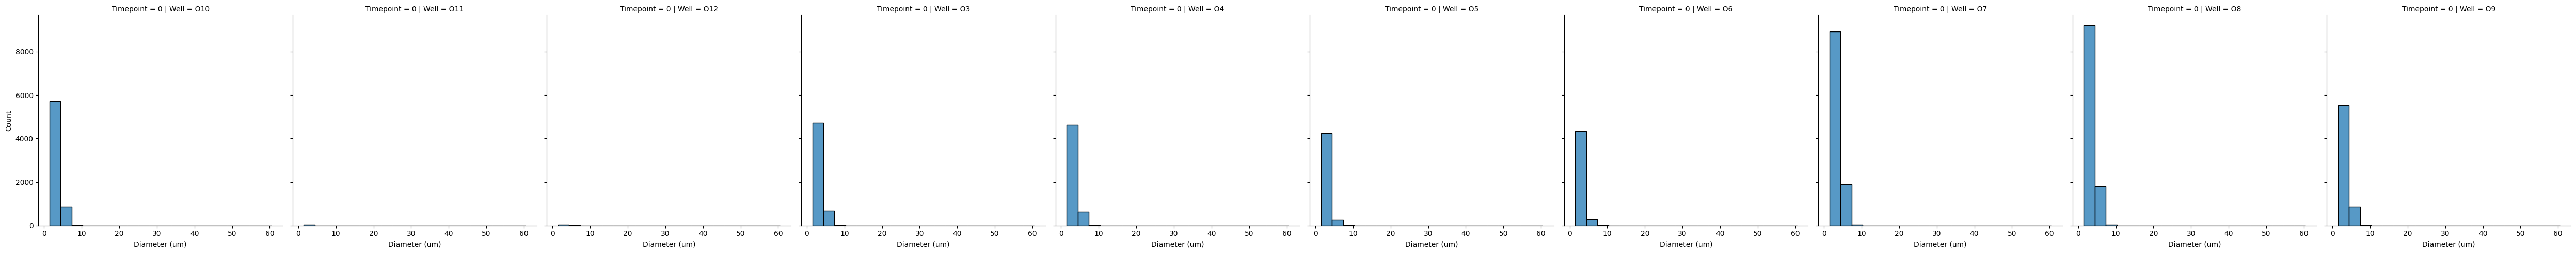

In [ ]:
m.plot_size(data)

## Fogplots

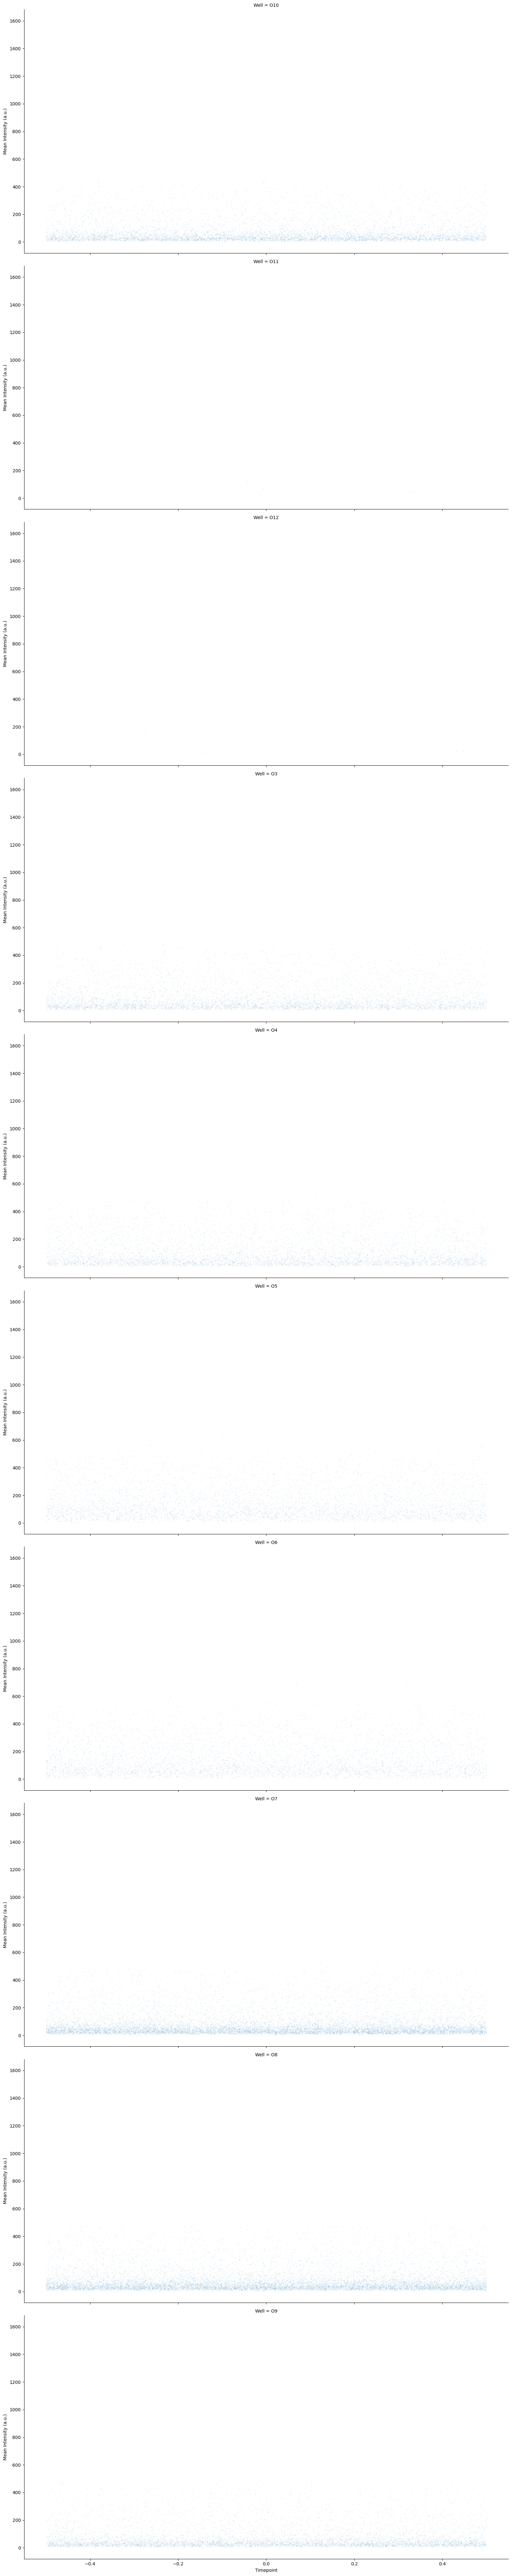

In [ ]:
m.plot_fogplot(data)

## Plotting for 4.5hr data

In [ ]:
last_timepoint = data['Timepoint'].max()

dye_leakage_data = data[data['Well'].isin(['O3','O4', 'O5', 'O6'])].copy()

# Filter for liposomes larger than 10 um in Diameter (Equivalent)
dye_leakage_data = dye_leakage_data[dye_leakage_data['Diameter (Equivalent) (um)'] > 5]

# Filter for the last time point
dye_leakage_data = dye_leakage_data[dye_leakage_data['Timepoint'] == last_timepoint]

# Pool K3 and K4 together as 'Neg Control', and K5 and K6 as 'Pos Control'
dye_leakage_data['Well'] = dye_leakage_data['Well'].replace({'O3': 'Neg Control', 'O4': 'Neg Control', 'O5': 'Pos Control', 'O6': 'Pos Control'})


In [ ]:
print(data['Timepoint'].unique())
print(data['Timepoint'].dtype)
print(last_timepoint)

[0]
int64
0


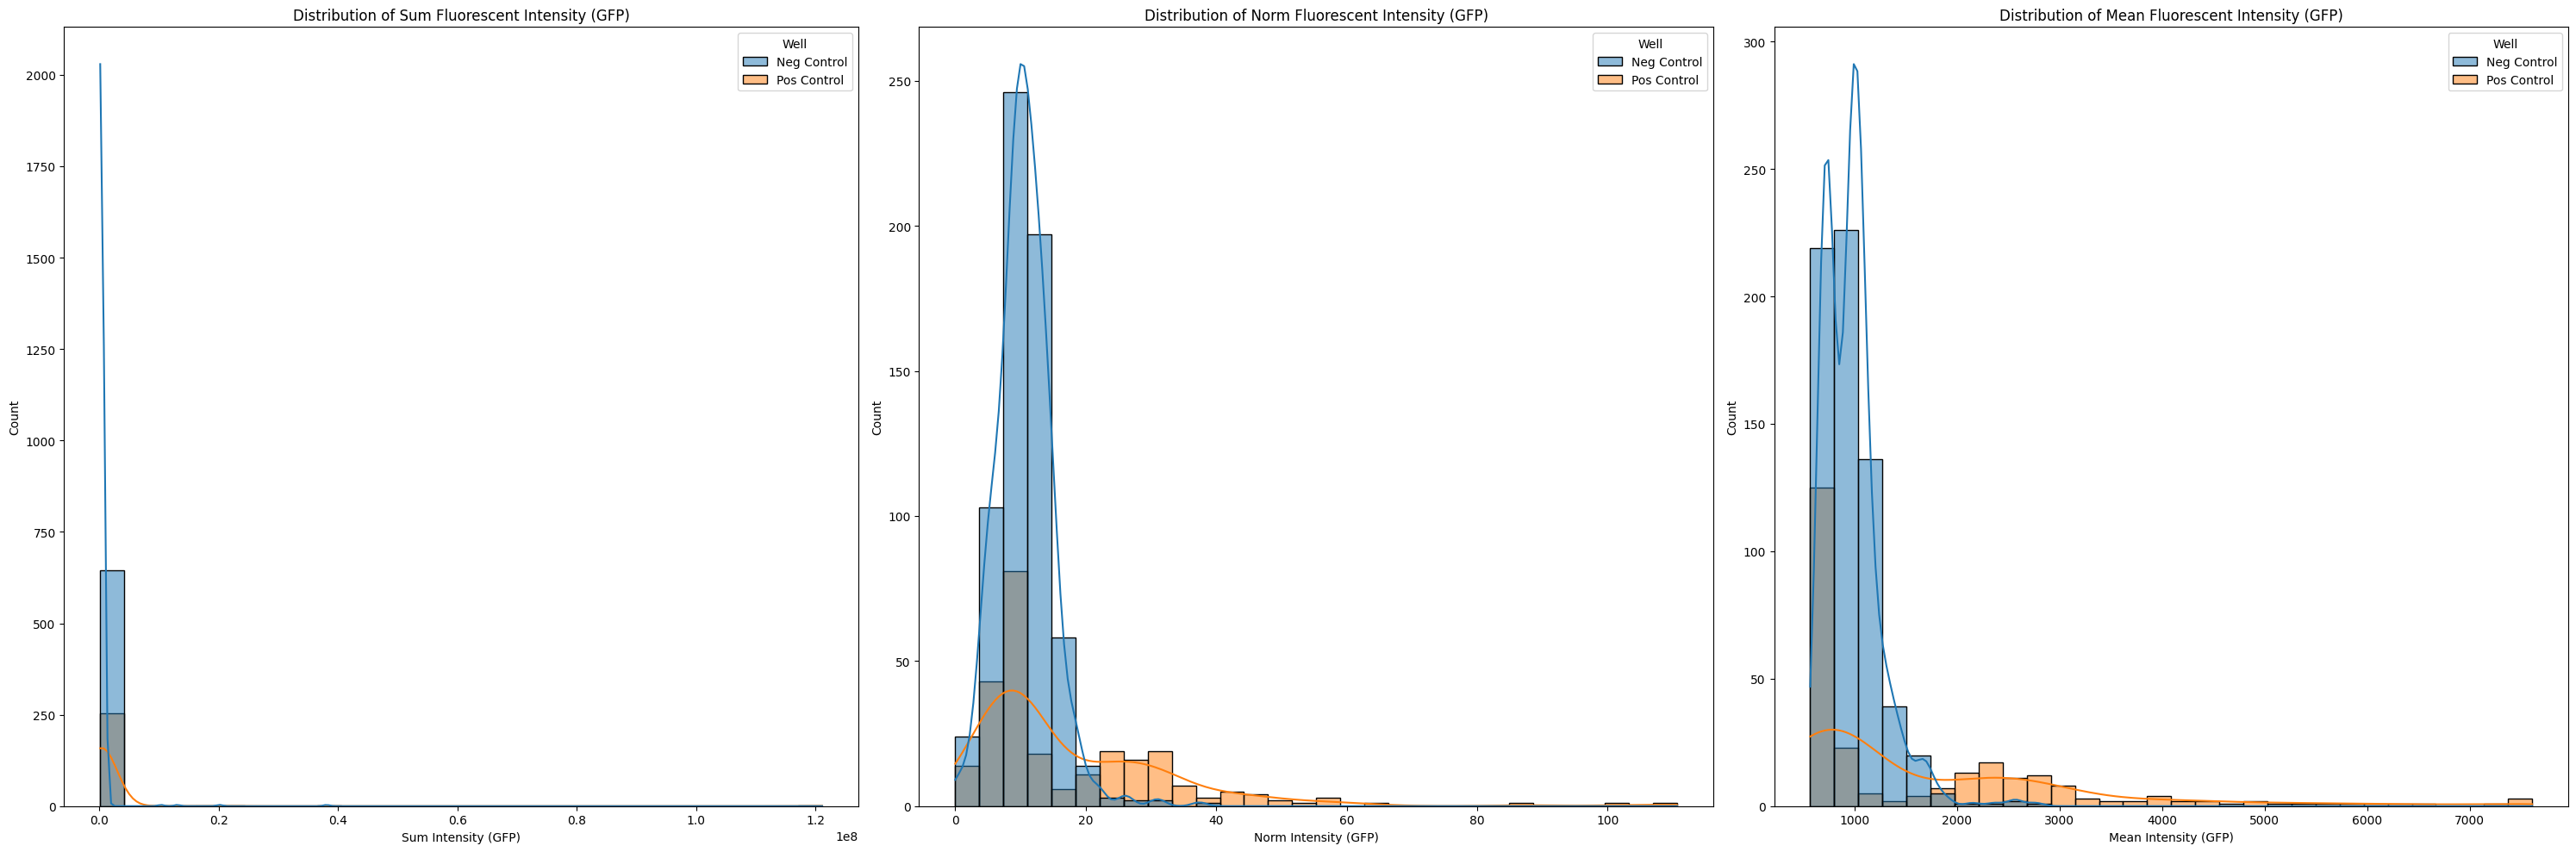

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

sns.histplot(data=dye_leakage_data, x='Intensity Sum (GFP)', hue='Well', kde=True, bins=30, ax=axes[0])
axes[0].set_title('Distribution of Sum Fluorescent Intensity (GFP)')
axes[0].set_xlabel('Sum Intensity (GFP)')
axes[0].set_ylabel('Count')

sns.histplot(data=dye_leakage_data, x='Intensity Norm (GFP)', hue='Well', kde=True, bins=30, ax=axes[1])
axes[1].set_title('Distribution of Norm Fluorescent Intensity (GFP)')
axes[1].set_xlabel('Norm Intensity (GFP)')
axes[1].set_ylabel('Count')

sns.histplot(data=dye_leakage_data, x='Intensity Mean (GFP)', hue='Well', kde=True, bins=30, ax=axes[2])
axes[2].set_title('Distribution of Mean Fluorescent Intensity (GFP)')
axes[2].set_xlabel('Mean Intensity (GFP)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

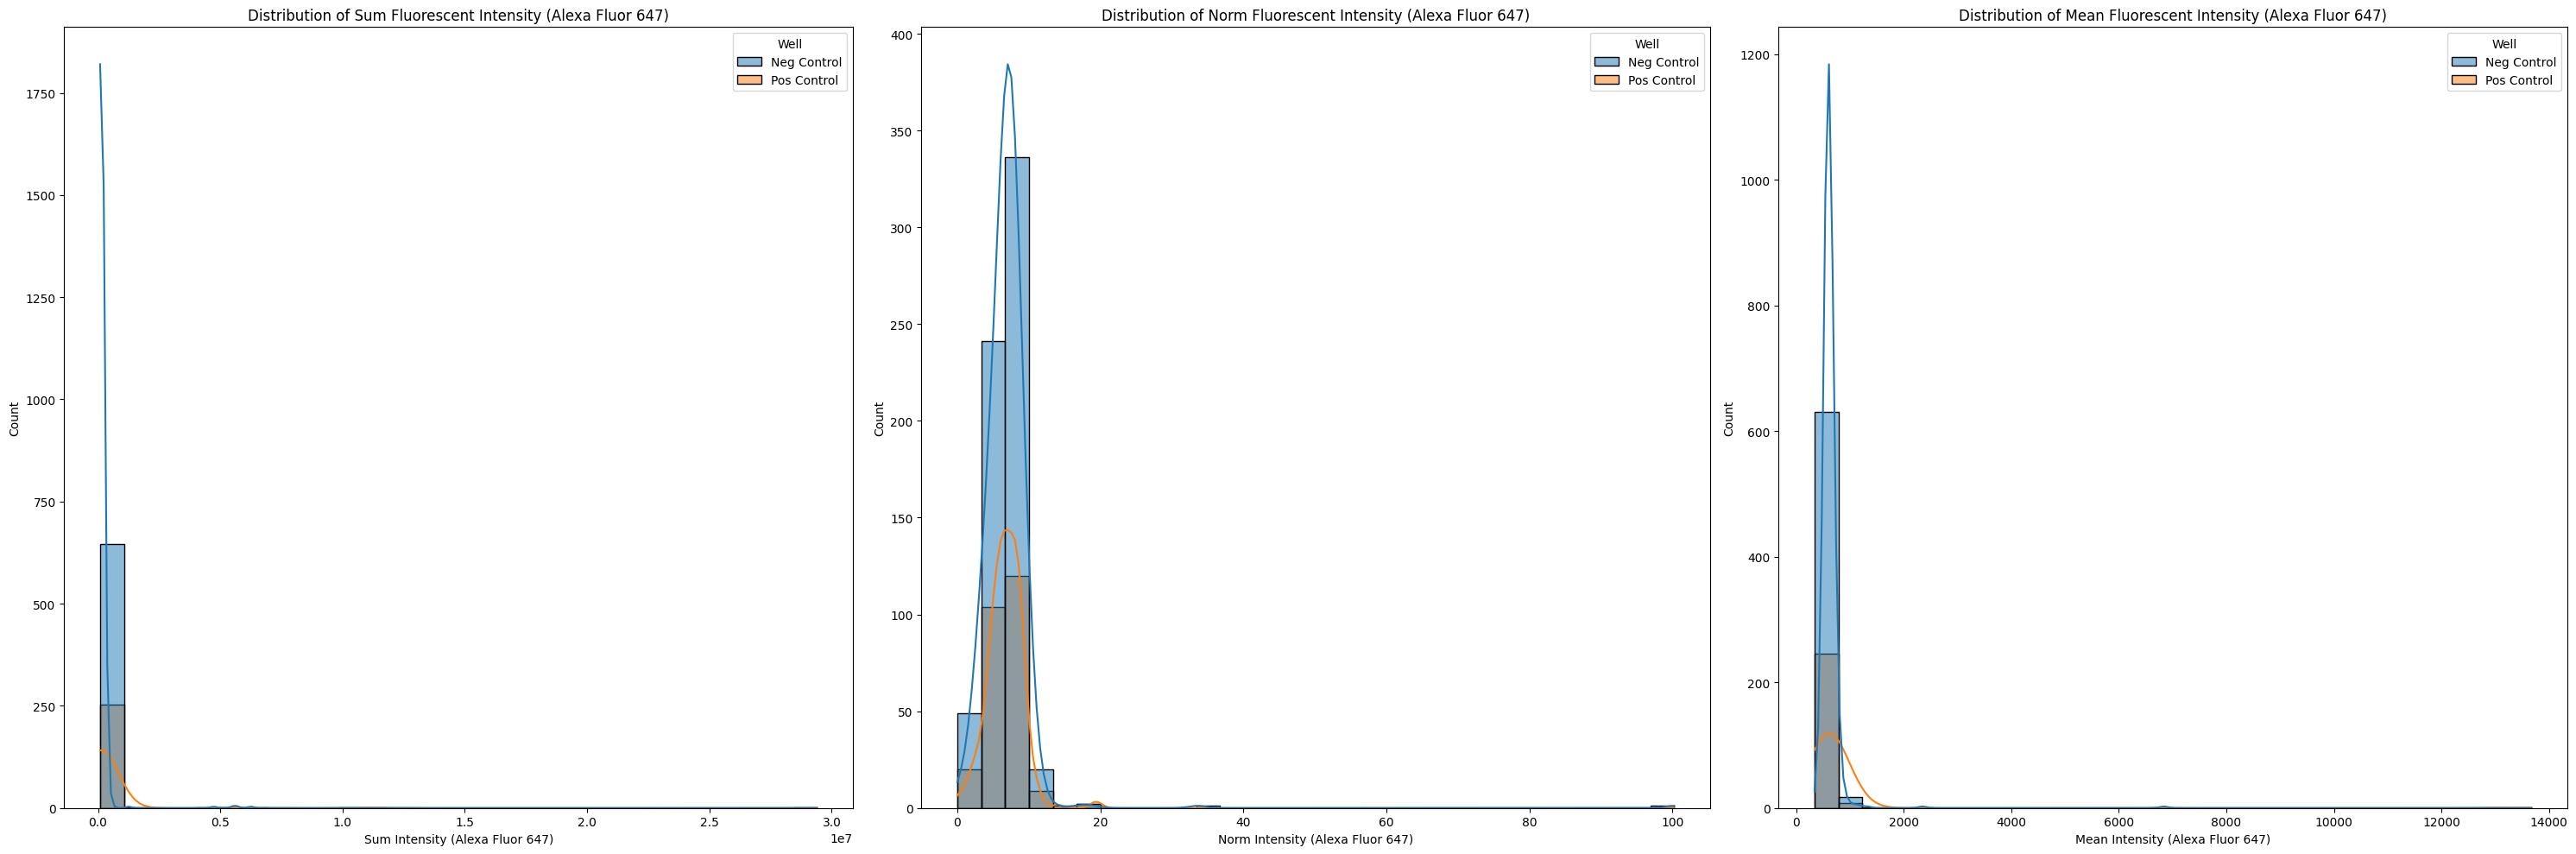

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

sns.histplot(data=dye_leakage_data, x='Intensity Sum (Alexa Fluor 647)', hue='Well', kde=True, bins=30, ax=axes[0])
axes[0].set_title('Distribution of Sum Fluorescent Intensity (Alexa Fluor 647)')
axes[0].set_xlabel('Sum Intensity (Alexa Fluor 647)')
axes[0].set_ylabel('Count')

sns.histplot(data=dye_leakage_data, x='Intensity Norm (Alexa Fluor 647)', hue='Well', kde=True, bins=30, ax=axes[1])
axes[1].set_title('Distribution of Norm Fluorescent Intensity (Alexa Fluor 647)')
axes[1].set_xlabel('Norm Intensity (Alexa Fluor 647)')
axes[1].set_ylabel('Count')

sns.histplot(data=dye_leakage_data, x='Intensity Mean (Alexa Fluor 647)', hue='Well', kde=True, bins=30, ax=axes[2])
axes[2].set_title('Distribution of Mean Fluorescent Intensity (Alexa Fluor 647)')
axes[2].set_xlabel('Mean Intensity (Alexa Fluor 647)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

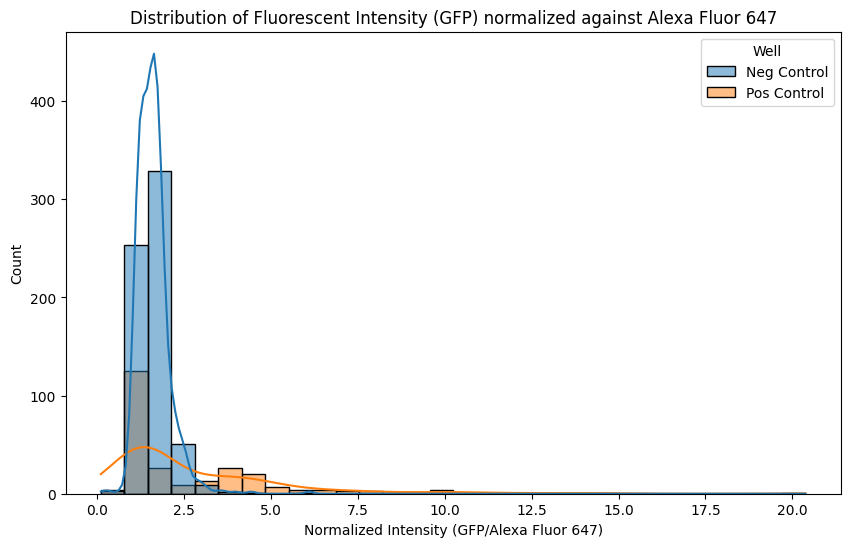

In [ ]:
# Rename Well labels for legend


dye_leakage_data['Normalized Intensity (GFP)'] = dye_leakage_data['Intensity Mean (GFP)'] / dye_leakage_data['Intensity Mean (Alexa Fluor 647)']

plt.figure(figsize=(10, 6))
sns.histplot(data=dye_leakage_data, x='Normalized Intensity (GFP)', hue='Well', kde=True, bins=30)
plt.title('Distribution of Fluorescent Intensity (GFP) normalized against Alexa Fluor 647')
plt.xlabel('Normalized Intensity (GFP/Alexa Fluor 647)')
plt.ylabel('Count')
plt.show()

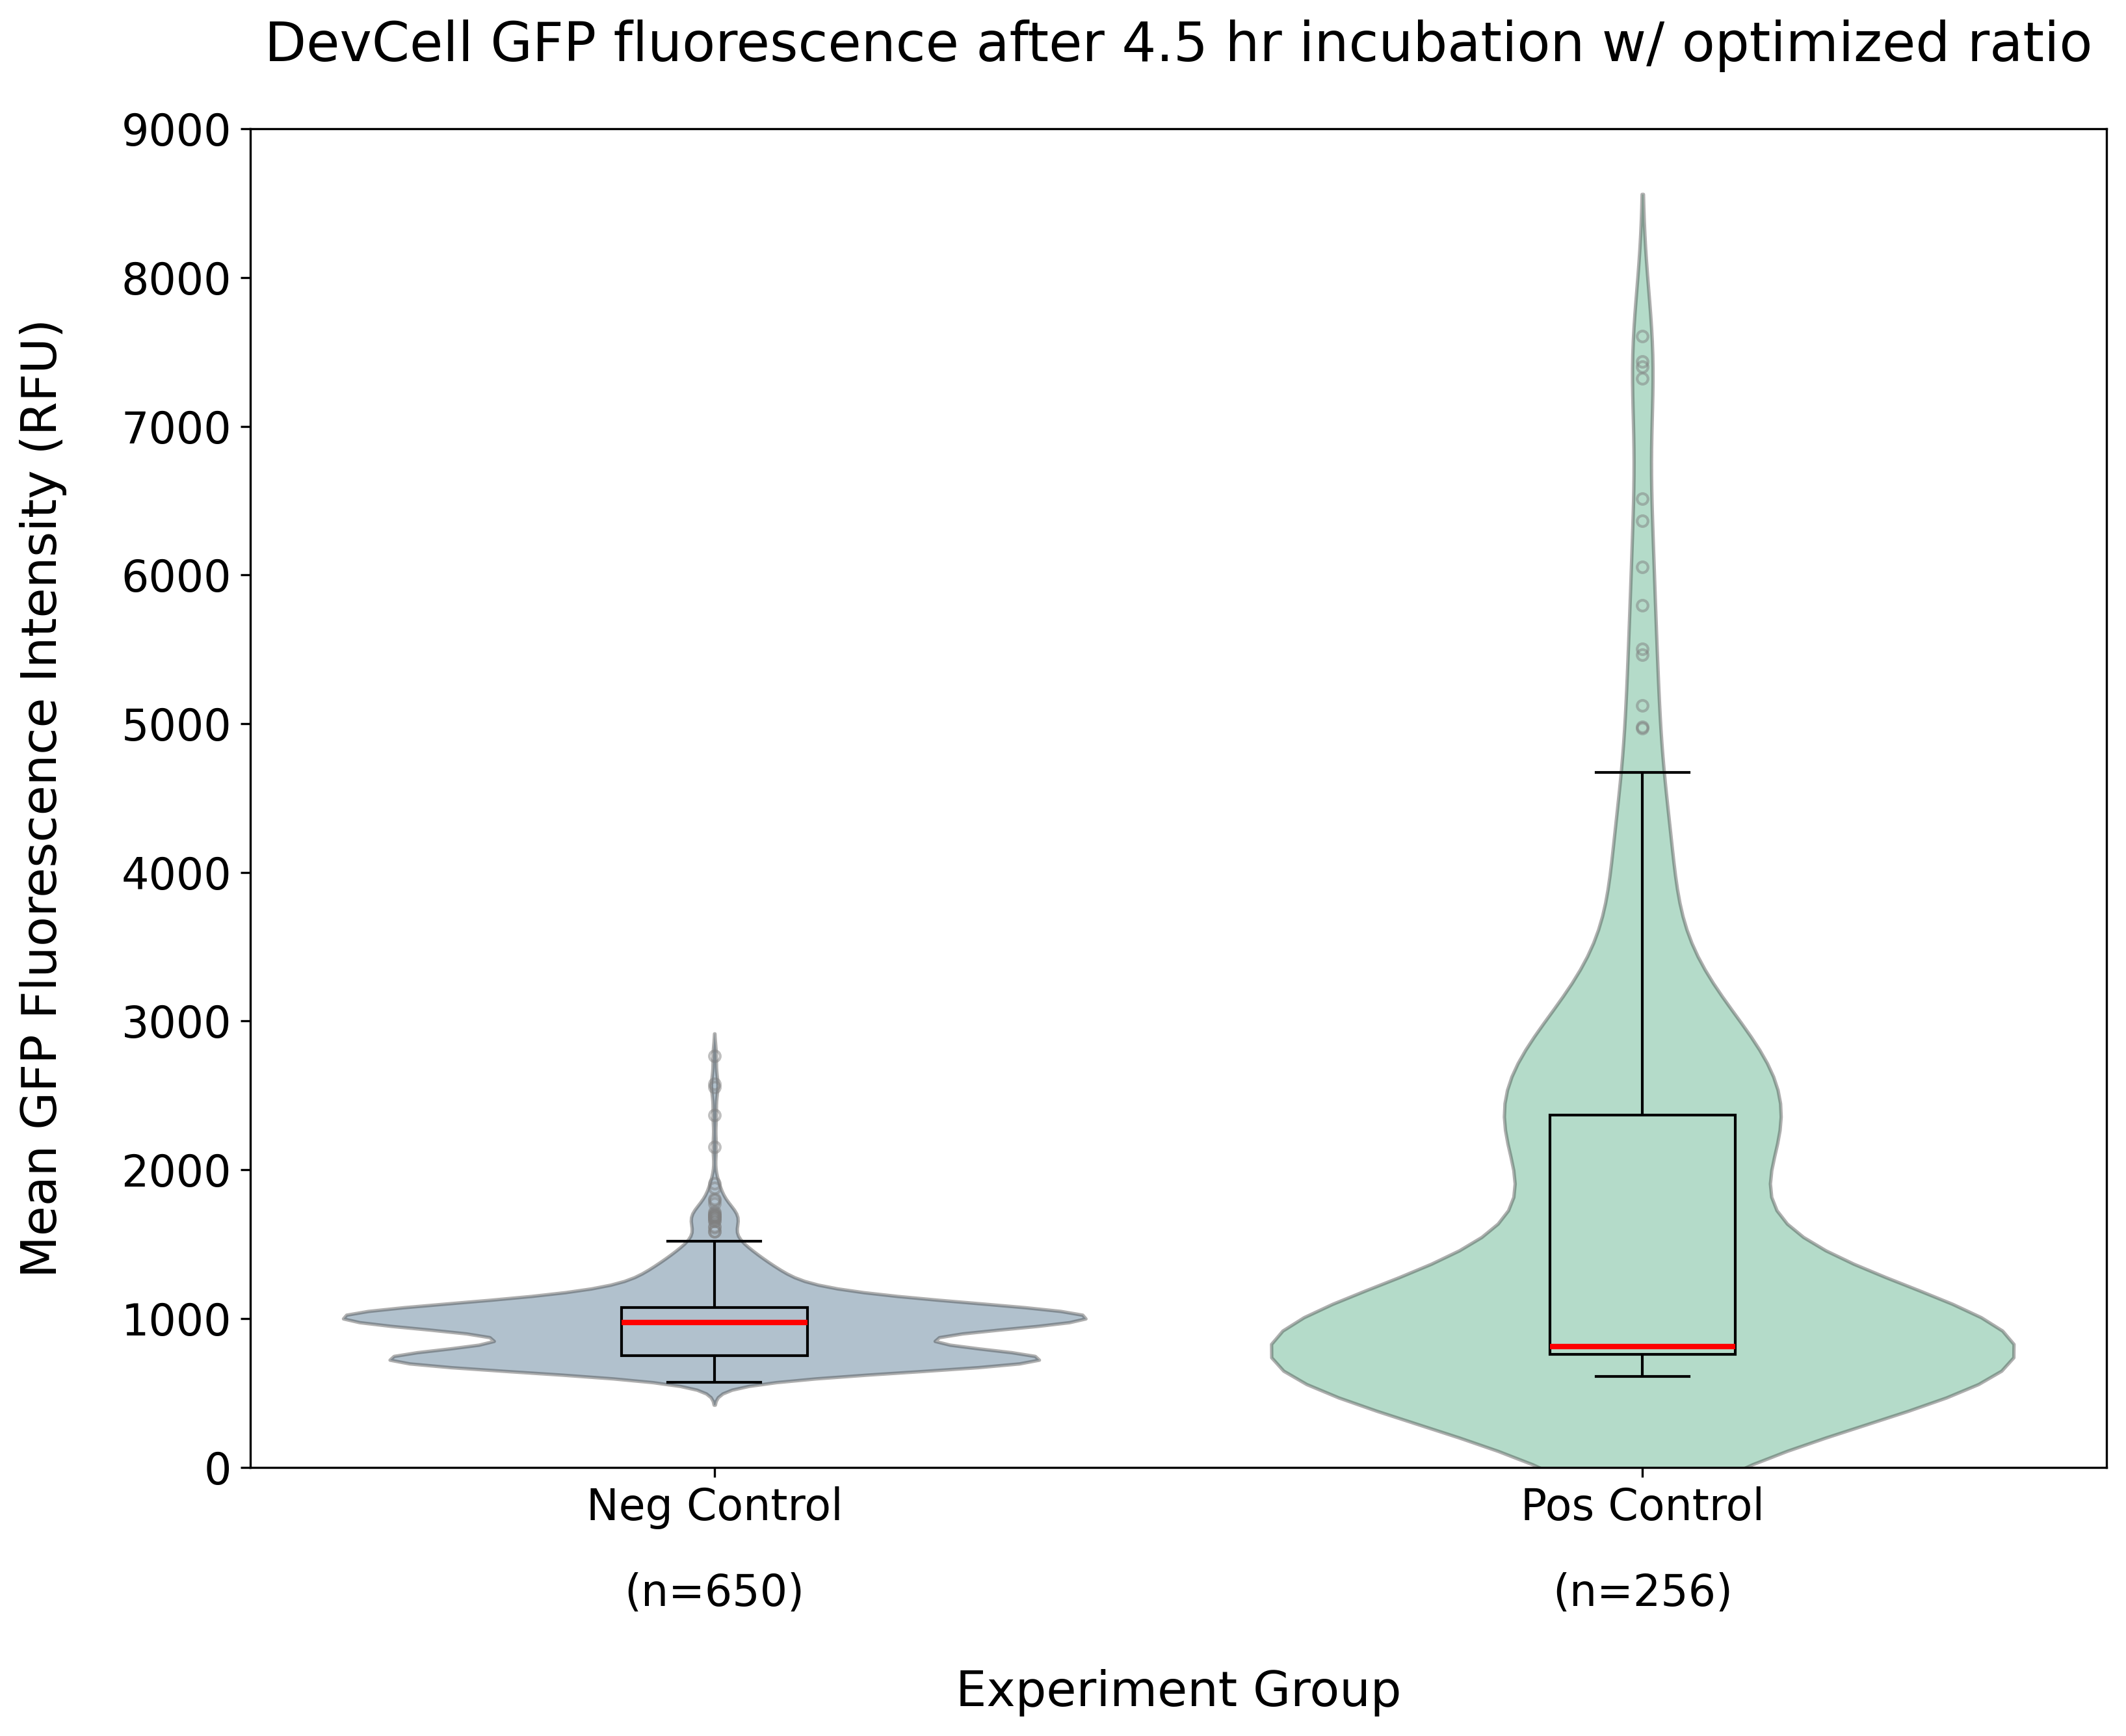

In [ ]:
#| label: fig7-quantified-gfp-4-5hr

fig, axes = plt.subplots(1, 1, figsize=(11, 9), dpi=300)

# Define the desired order for 'Well' categories
well_order = ['Neg Control', 'Pos Control']
dye_leakage_data['Well'] = pd.Categorical(dye_leakage_data['Well'], categories=well_order, ordered=True)

# Calculate group counts for the x-axis labels
counts = dye_leakage_data['Well'].value_counts()
# Add double newline characters for distinct vertical spacing
new_labels = [f"{group}\n\n(n={counts[group]})" for group in well_order]

# 1. Violin plot as the background
sns.violinplot(
    data=dye_leakage_data,
    x='Well',
    y='Intensity Mean (GFP)',
    hue='Well',
    ax=axes,
    palette='viridis',
    inner=None,
    alpha=0.4,
    legend=False
)

# 2. Box plot overlaid on top (made narrower with a distinct style)
sns.boxplot(
    data=dye_leakage_data,
    x='Well',
    y='Intensity Mean (GFP)',
    ax=axes,
    width=0.2,
    boxprops={'facecolor': 'none', 'edgecolor': 'black', 'zorder': 2},
    whiskerprops={'color': 'black', 'zorder': 2},
    capprops={'color': 'black', 'zorder': 2},
    medianprops={'color': 'red', 'linewidth': 2, 'zorder': 3},
    showfliers=True,
    flierprops={'marker': 'o', 'markersize': 4, 'markeredgecolor': 'gray', 'alpha': 0.5}
)

# Style axes
axes.set_title('DevCell GFP fluorescence after 4.5 hr incubation w/ optimized ratio', fontsize=20, pad=25)
axes.set_xlabel('Experiment Group', fontsize=18, labelpad=20)
axes.set_ylabel('Mean GFP Fluorescence Intensity (RFU)', fontsize=18, labelpad=20)

# Apply the custom labels with larger fonts and explicit line spacing
axes.set_xticks(range(len(well_order)))
axes.set_xticklabels(new_labels, fontsize=16, linespacing=1)
axes.tick_params(axis='y', labelsize=16)
axes.set_ylim(0, 9000)

plt.tight_layout()

# Save the figure as a 300 DPI image
plt.savefig('devcell_gfp_fluorescence.png', dpi=300)
plt.show()

##Plotting for 1.5hr data

In [ ]:
data = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/2026-07-30-Day4_v3_%2B1.5hr_2026-07-30_16-17-29.737603.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

# data = data.merge(platemap, on="Well")
# data = data.sort_values(by=["Experiment", "Name", "Timepoint"])


last_timepoint = data['Timepoint'].max()

dye_leakage_data_1 = data[data['Well'].isin(['O3','O4', 'O5', 'O6'])].copy()

# Filter for liposomes larger than 10 um in Diameter (Equivalent)
dye_leakage_data_1 = dye_leakage_data_1[dye_leakage_data_1['Diameter (Equivalent) (um)'] > 5]

# Filter for the last time point
dye_leakage_data_1 = dye_leakage_data_1[dye_leakage_data_1['Timepoint'] == last_timepoint]

# Pool K3 and K4 together as 'Neg Control', and K5 and K6 as 'Pos Control'
dye_leakage_data_1['Well'] = dye_leakage_data_1['Well'].replace({'O3': 'Neg Control', 'O4': 'Neg Control', 'O5': 'Pos Control', 'O6': 'Pos Control'})

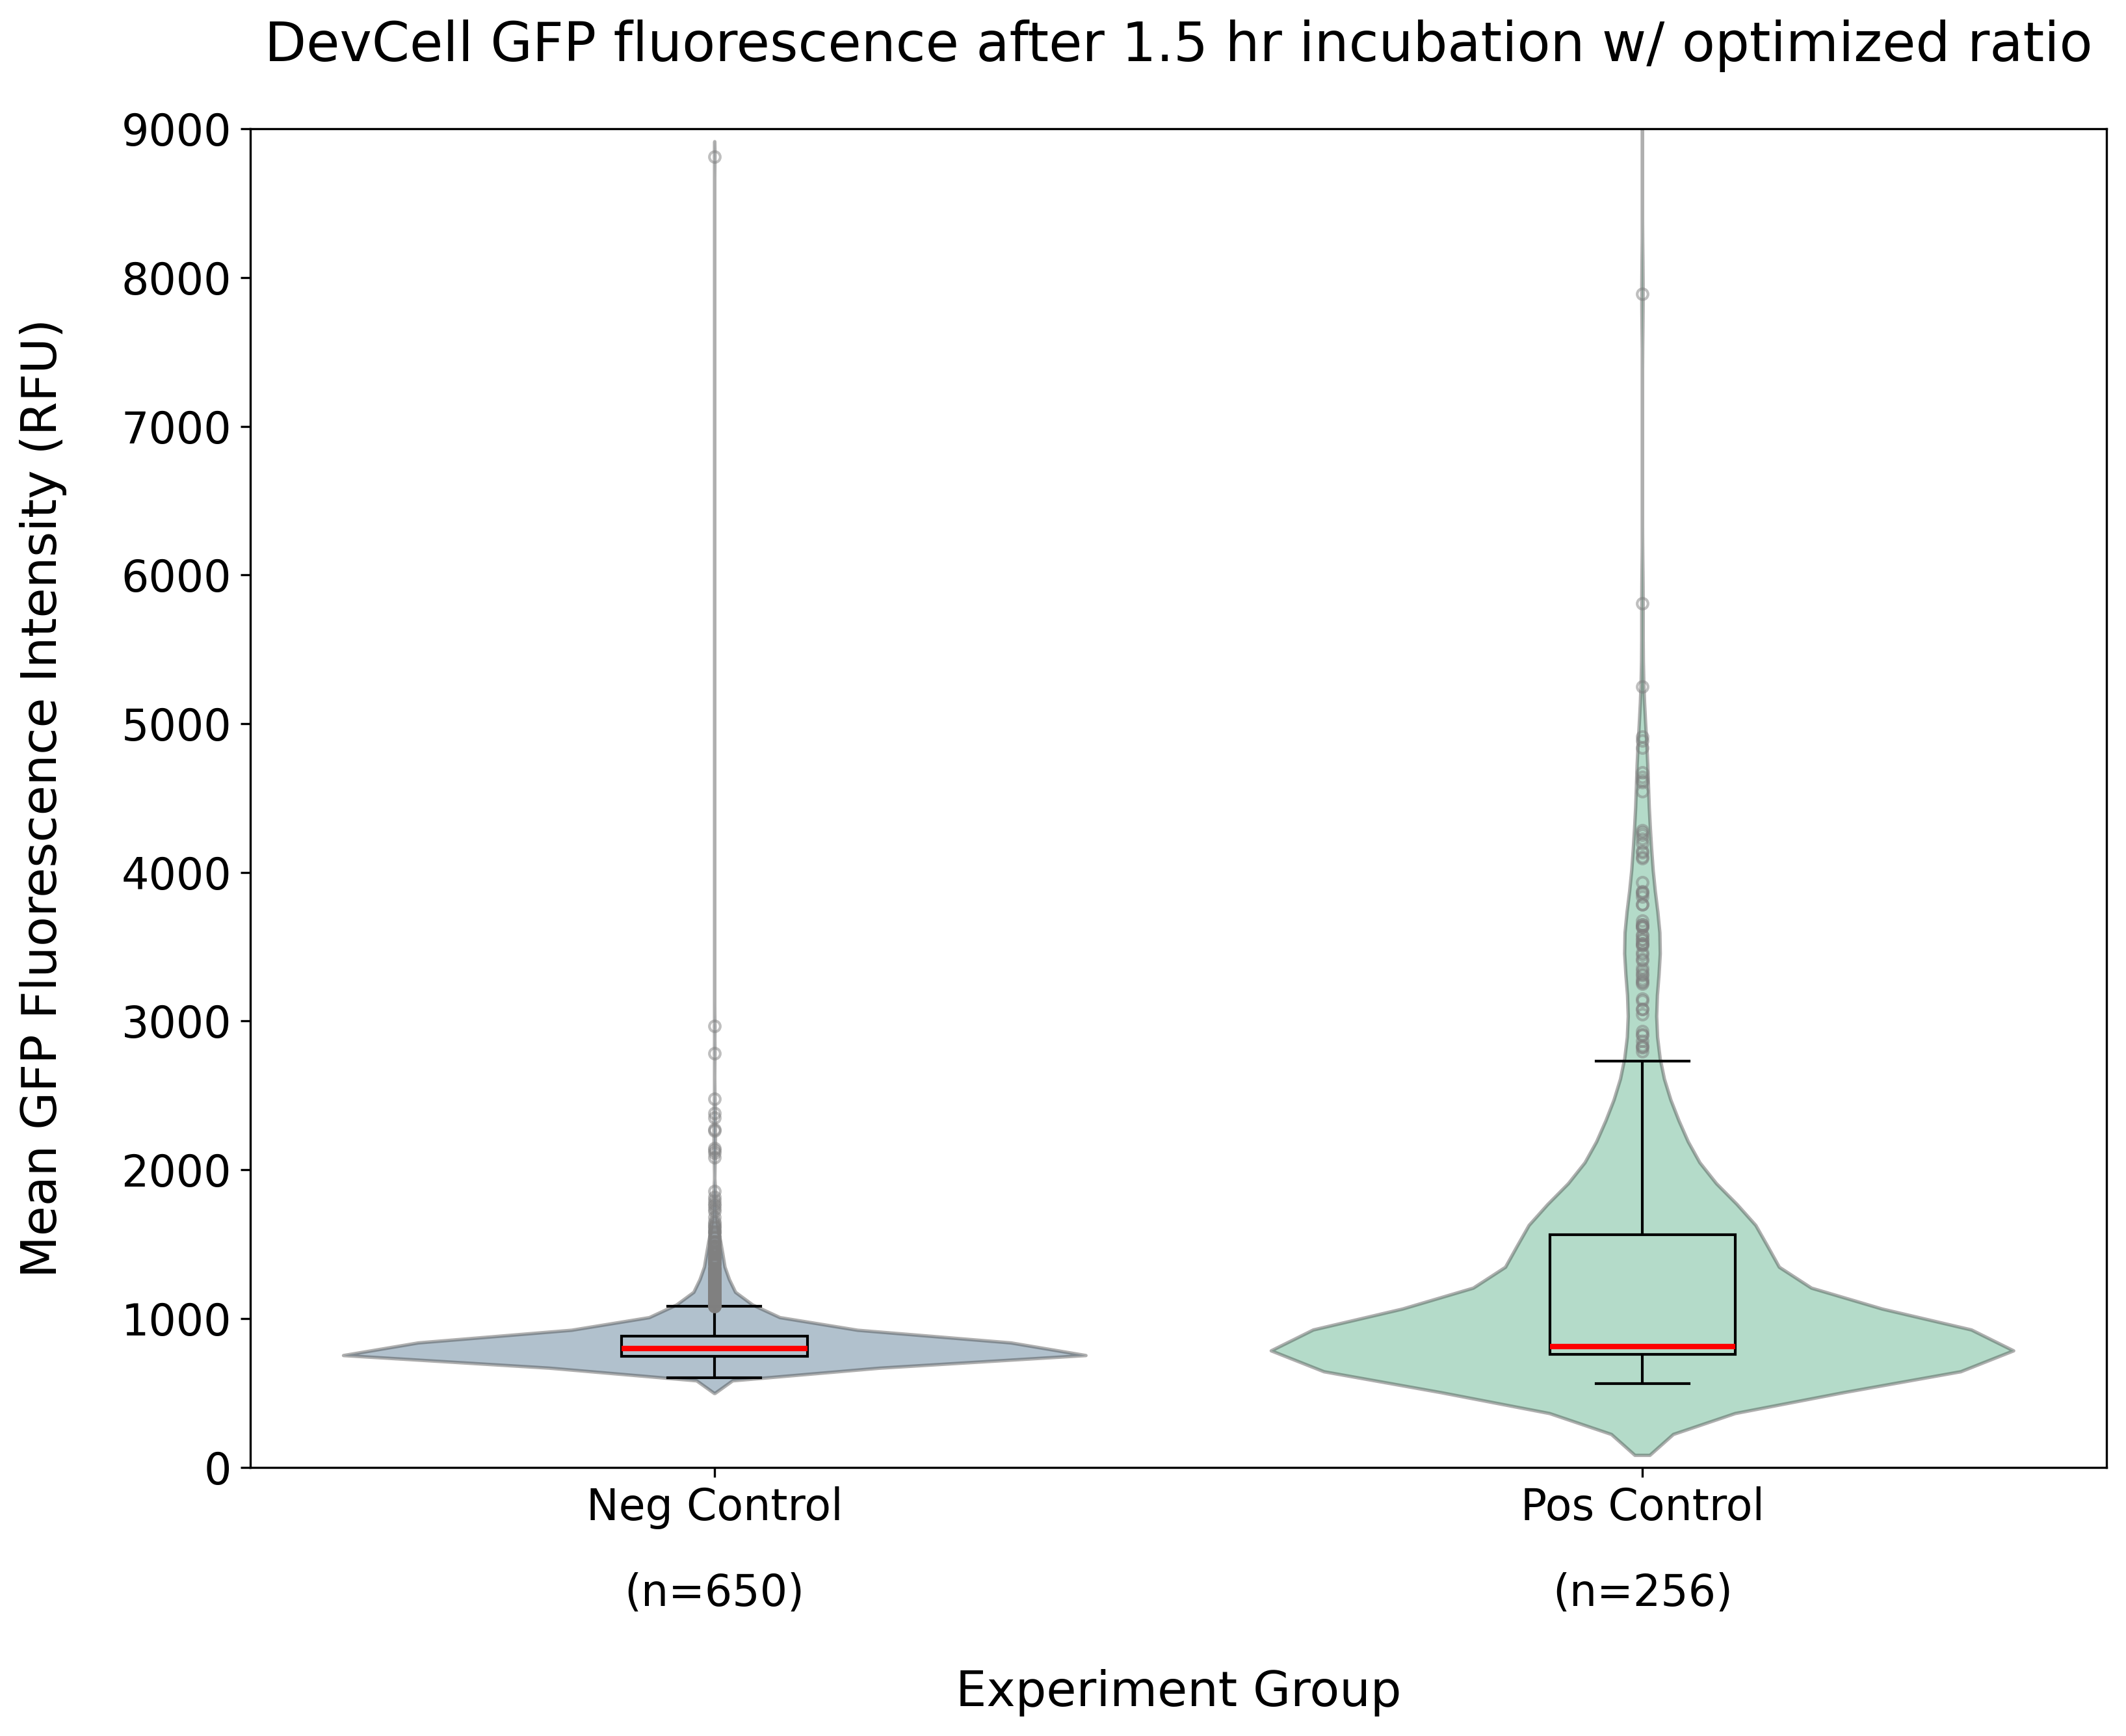

In [ ]:
#| label: fig6-quantified-gfp-1-5hr

fig, axes = plt.subplots(1, 1, figsize=(11, 9), dpi=300)

# Define the desired order for 'Well' categories
well_order = ['Neg Control', 'Pos Control']
dye_leakage_data_1['Well'] = pd.Categorical(dye_leakage_data_1['Well'], categories=well_order, ordered=True)

# Calculate group counts for the x-axis labels
counts = dye_leakage_data['Well'].value_counts()
# Add double newline characters for distinct vertical spacing
new_labels = [f"{group}\n\n(n={counts[group]})" for group in well_order]

# 1. Violin plot as the background
sns.violinplot(
    data=dye_leakage_data_1,
    x='Well',
    y='Intensity Mean (GFP)',
    hue='Well',
    ax=axes,
    palette='viridis',
    inner=None,
    alpha=0.4,
    legend=False
)

# 2. Box plot overlaid on top (made narrower with a distinct style)
sns.boxplot(
    data=dye_leakage_data_1,
    x='Well',
    y='Intensity Mean (GFP)',
    ax=axes,
    width=0.2,
    boxprops={'facecolor': 'none', 'edgecolor': 'black', 'zorder': 2},
    whiskerprops={'color': 'black', 'zorder': 2},
    capprops={'color': 'black', 'zorder': 2},
    medianprops={'color': 'red', 'linewidth': 2, 'zorder': 3},
    showfliers=True,
    flierprops={'marker': 'o', 'markersize': 4, 'markeredgecolor': 'gray', 'alpha': 0.5}
)

# Style axes
axes.set_title('DevCell GFP fluorescence after 1.5 hr incubation w/ optimized ratio', fontsize=20, pad=25)
axes.set_xlabel('Experiment Group', fontsize=18, labelpad=20)
axes.set_ylabel('Mean GFP Fluorescence Intensity (RFU)', fontsize=18, labelpad=20)

# Apply the custom labels with larger fonts and explicit line spacing
axes.set_xticks(range(len(well_order)))
axes.set_xticklabels(new_labels, fontsize=16, linespacing=1)
axes.tick_params(axis='y', labelsize=16)
axes.set_ylim(0, 9000)

plt.tight_layout()

# Save the figure as a 300 DPI image
plt.savefig('devcell_gfp_fluorescence.png', dpi=300)
plt.show()